<a href="https://colab.research.google.com/github/dandaocta1/Visualisasi-Data/blob/main/DataVisualization_2418008.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **VISUALISASI DATA KARYAWAN**



## **1. Import Libraries**

In [1]:
import pandas as pd  # Library untuk pengolahan dan analisis data berbentuk tabel
import numpy as np  # Library untuk operasi komputasi numerik
import matplotlib.pyplot as plt  # Modul utama untuk pembuatan visualisasi grafik
import seaborn as sns  # Library visualisasi statistik berbasis matplotlib

## **2. Load DataSet Karyawan**

In [2]:
# Membaca file Excel yang diunggah langsung di penyimpanan Colab
dataset = pd.read_excel('Data Karyawan.xlsx')

print('Ukuran dataset: %d baris dan %d kolom\n' % dataset.shape)  # Menampilkan total baris dan kolom
print('Lima data teratas:')
print(dataset.head())  # Menampilkan 5 baris pertama data

Ukuran dataset: 100 baris dan 8 kolom

Lima data teratas:
  ID KARYAWAN             NAMA DEPARTEMEN  USIA      GAJI  RATING KERJA  \
0        E001     Budi Santoso         IT    28  10000000          Baik   
1        E002  Revanka Antonio        HRD    25   7000000    Cukup Baik   
2        E003     Rehan Andika         IT    21  10000000        Kurang   
3        E004     Rizki Candra    Finance    27   6000000          Baik   
4        E005    Hun Mie Sheng        HRD    27   7000000  Sangat Buruk   

      USIA.1  GAJI.1  
0  Produktif  Tinggi  
1       Muda  Sedang  
2       Muda  Tinggi  
3  Produktif  Sedang  
4  Produktif  Sedang  


## **3. Eksplorasi Informasi Dataset**

In [3]:
print('Informasi Struktur dan Tipe Data:')
dataset.info()  # Menampilkan tipe data serta jumlah data yang terisi

print('\nRingkasan Statistik Data Numerik:')
print(dataset.describe())  # Menampilkan nilai rata-rata, min, max, dan kuartil

Informasi Struktur dan Tipe Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   ID KARYAWAN   100 non-null    object
 1   NAMA          100 non-null    object
 2   DEPARTEMEN    100 non-null    object
 3   USIA          100 non-null    int64 
 4   GAJI          100 non-null    int64 
 5   RATING KERJA  100 non-null    object
 6   USIA.1        100 non-null    object
 7   GAJI.1        100 non-null    object
dtypes: int64(2), object(6)
memory usage: 6.4+ KB

Ringkasan Statistik Data Numerik:
             USIA          GAJI
count  100.000000  1.000000e+02
mean    31.780000  7.660000e+06
std      8.470484  1.485417e+06
min     19.000000  6.000000e+06
25%     25.000000  6.000000e+06
50%     29.000000  7.000000e+06
75%     37.000000  8.000000e+06
max     53.000000  1.000000e+07


## **4. Agregasi Data per Departemen**

In [4]:
# Mengelompokkan data berdasarkan DEPARTEMEN dan menghitung total serta rata-rata GAJI
gaji_dept = dataset.groupby('DEPARTEMEN')['GAJI'].agg(['sum', 'mean', 'count']).reset_index()
gaji_dept.columns = ['DEPARTEMEN', 'TOTAL_GAJI', 'RATA_GAJI', 'JUMLAH_KARYAWAN']

print('Tabel Agregasi per Departemen:')
print(gaji_dept)

Tabel Agregasi per Departemen:
  DEPARTEMEN  TOTAL_GAJI   RATA_GAJI  JUMLAH_KARYAWAN
0    Finance   174000000   6000000.0               29
1        HRD   154000000   7000000.0               22
2         IT   230000000  10000000.0               23
3  Marketing   208000000   8000000.0               26


## **5. Visualisasi 1 - Total Pengeluaran Gaji per Departemen**

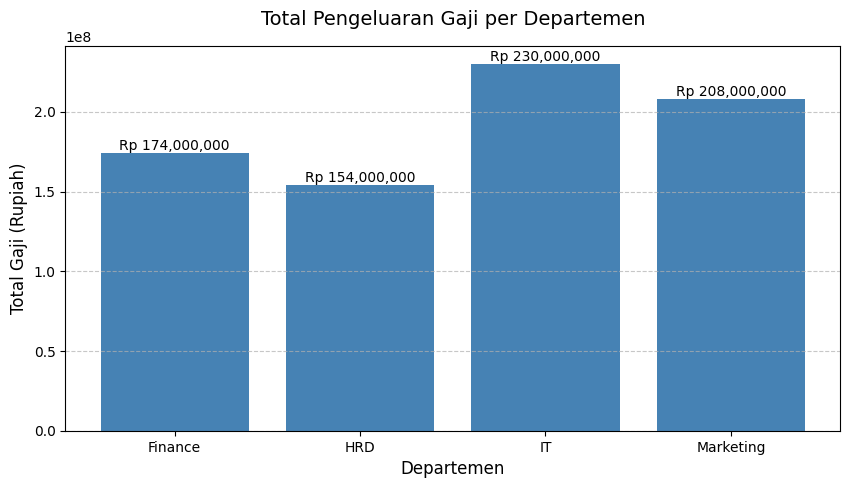

In [5]:
plt.figure(figsize=(10, 5))  # Menentukan ukuran kanvas

# Membuat bar chart total gaji per departemen
bars = plt.bar(gaji_dept['DEPARTEMEN'], gaji_dept['TOTAL_GAJI'], color='steelblue')

plt.title('Total Pengeluaran Gaji per Departemen', fontsize=14, pad=15)  # Judul grafik
plt.xlabel('Departemen', fontsize=12)  # Label sumbu X
plt.ylabel('Total Gaji (Rupiah)', fontsize=12)  # Label sumbu Y
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Menambahkan garis kisi-kisi

# Menambahkan label nilai di atas batang grafik
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, f'Rp {int(yval):,}', ha='center', va='bottom', fontsize=10)

plt.show()

## **6. Visualisasi 2 - Distribusi Rating Kerja Karyawan**

/tmp/ipykernel_927/1524877097.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=dataset, x='RATING KERJA', order=order_rating, palette='Blues_r')


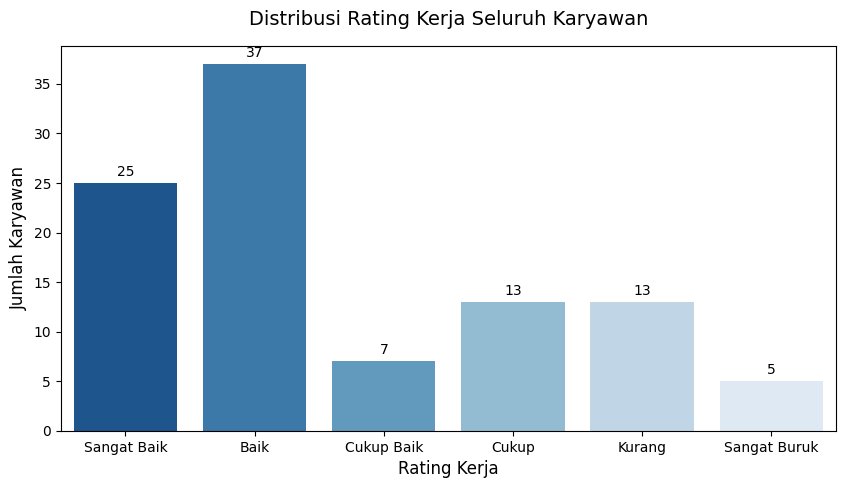

In [6]:
# Urutan kategori rating dari tertinggi ke terendah
order_rating = ['Sangat Baik', 'Baik', 'Cukup Baik', 'Cukup', 'Kurang', 'Sangat Buruk']

plt.figure(figsize=(10, 5))
ax = sns.countplot(data=dataset, x='RATING KERJA', order=order_rating, palette='Blues_r')

plt.title('Distribusi Rating Kerja Seluruh Karyawan', fontsize=14, pad=15)
plt.xlabel('Rating Kerja', fontsize=12)
plt.ylabel('Jumlah Karyawan', fontsize=12)

# Menambahkan label angka di atas setiap batang
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.show()

## **7. Visualisasi 3 - Grouped Bar Chart Kategori Usia per Departemen**

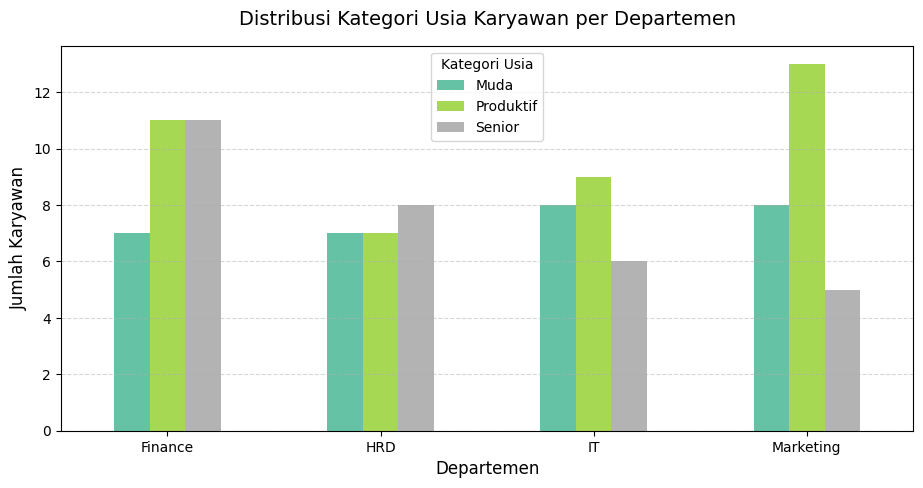

In [7]:
# Membuat tabel silang antara DEPARTEMEN dan Kategori USIA.1
usia_dept = pd.crosstab(dataset['DEPARTEMEN'], dataset['USIA.1'])

# Plotting grouped bar chart
usia_dept.plot(kind='bar', figsize=(11, 5), colormap='Set2')

plt.title('Distribusi Kategori Usia Karyawan per Departemen', fontsize=14, pad=15)
plt.xlabel('Departemen', fontsize=12)
plt.ylabel('Jumlah Karyawan', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Kategori Usia')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

## **8. Visualisasi 4 - Heatmap Korelasi Pearson (Usia vs Gaji)**

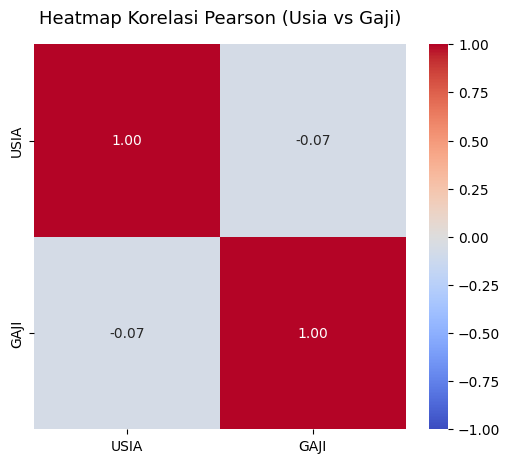

In [8]:
# Menhitung matriks korelasi Pearson
corr_matrix = dataset[['USIA', 'GAJI']].corr(method='pearson')

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)

plt.title('Heatmap Korelasi Pearson (Usia vs Gaji)', fontsize=13, pad=15)
plt.show()